### DSAI3204 IoT Application Development: Project

#### Maryam Mahaboob
#### Sensors: VOC, temperature & humidity (Arduino MKR IoT Carrier)

## Summary

**Goal:** statistical forecasting of VOC: outlier removal, stationarity checks (ADF, ACF/PACF), ARIMA / auto-ARIMA, exponential smoothing (ETS), Prophet, and a simple moving-average (SMA) baseline.

**Data:** `../data/raw/voc_raw.csv.gz` (1,121,175 raw readings, ~1 s apart). The last cell reads `../data/sensors_1min.csv`; in the original run it read the old `processed_data.csv` (3–7 June), so its saved outputs come from that file.

**Split:** chronological 80/20. **Horizon:** the whole test set in one go: about 2.9 days (224,235 steps) on the raw data, and 4,074 one-minute steps spanning 75.4 hours on the 1-minute data. The last cell only plots a 100-minute forecast (no metric).

**Key result (saved output) vs baselines, 1-minute data:**

| Model | RMSE | MAE |
|---|---|---|
| ARIMA(1,1,1) | 0.2115 | 0.1476 |
| ETS (additive trend) | 0.2123 | 0.1480 |
| Prophet | 0.2271 | 0.1611 |
| SMA(5) baseline (in the notebook) | 0.2085 | 0.1463 |
| Train-mean baseline | **0.2044** | **0.1445** |

The train-mean baseline was computed later, during a review of the project. None of the models beat the simple baselines, and all have R² < 0 on this long horizon. On the raw data, auto-ARIMA picked ARIMA(0,1,0), which is exactly "repeat the last value" (RMSE 0.3664).

**Caveats**
- Outliers are found with a z-score on the **full** series (test included), and outliers are removed from the test set too, so "cleaned" and "original" results are not comparable.
- The log-ARIMA(3,0,3) result (RMSE 0.1009) did **not converge**; don't use it.
- "Number of duplicated rows" counts repeated VOC *values*, not duplicate records.
- Cells were run out of order in the original session.
- Removed during cleanup: a cell that used **synthetic random data** (its results table described noise, not the sensor), and a duplicate plot cell.
- Needs `pmdarima` and `prophet`. Uses `fillna(method=...)` and `'1T'`, which newer pandas versions deprecate.


##### CONTENTS: voc Forecasting

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
from pmdarima import auto_arima
from prophet import Prophet
from sklearn.metrics import mean_absolute_error, root_mean_squared_error
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller

sns.set_theme()  # Set seaborn theme for consistent plot styling

# Show warnings as "Category: message" without the library file path
warnings.formatwarning = lambda message, category, *args, **kwargs: f"{category.__name__}: {message}\n"

FIG_DIR = Path("../figures")
FIG_DIR.mkdir(exist_ok=True)


def report(name, y_true, y_pred):
    """Print RMSE and MAE of one forecast and return them."""
    rmse = root_mean_squared_error(y_true, np.asarray(y_pred))
    mae = mean_absolute_error(y_true, np.asarray(y_pred))
    print(f"{name:<40} RMSE: {rmse:.4f}  MAE: {mae:.4f}")
    return rmse, mae

Importing plotly failed. Interactive plots will not work.


In [2]:
# ======================================
# LOAD AND PREPROCESS TIME SERIES DATA
# ======================================

# Load dataset
df = pd.read_csv("../data/raw/voc_raw.csv.gz")

# Convert 'time' column to datetime format
df['time'] = pd.to_datetime(df['time'], format="ISO8601", utc=True)

# Set 'time' as the index
df.set_index('time', inplace=True)

# Display first few rows
print(df.head())

# Dataset shape
print("Shape of dataset:", df.shape)

# Check for missing values
print("Missing values:\n", df.isnull().sum())

# Check for duplicates
print("Number of duplicated rows:", df.duplicated().sum())

                                        value
time                                         
2025-06-03 00:00:00.150610304+00:00  0.545338
2025-06-03 00:00:01.196991900+00:00  0.545338
2025-06-03 00:00:02.240958760+00:00  0.545338
2025-06-03 00:00:03.597936680+00:00  0.541409
2025-06-03 00:00:04.537670287+00:00  0.541409
Shape of dataset: (1121175, 1)
Missing values:
 value    0
dtype: int64
Number of duplicated rows: 1026684


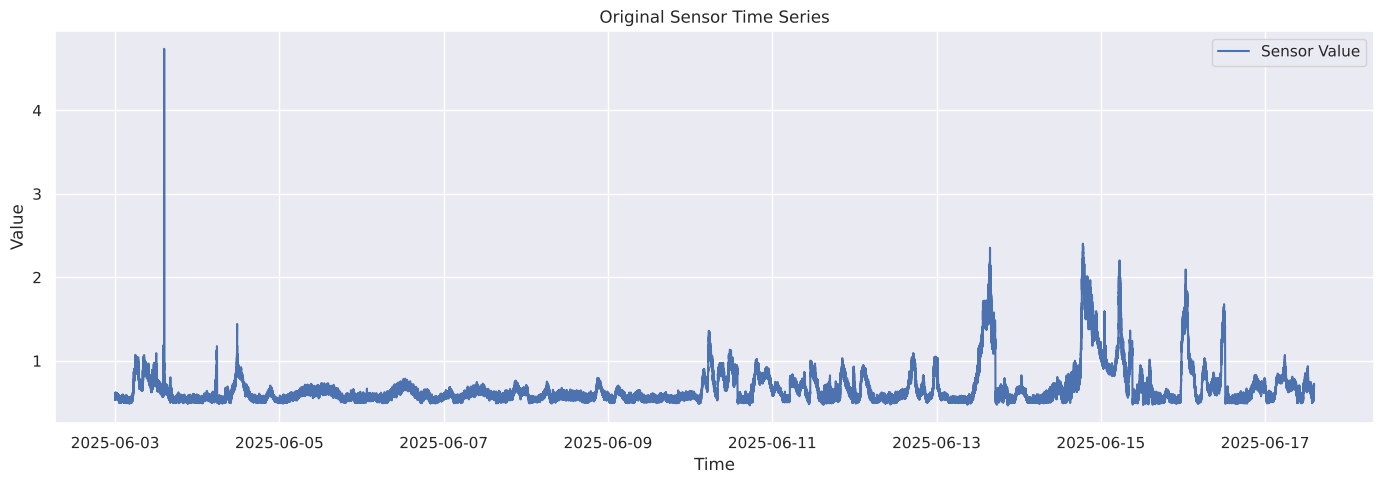

In [3]:
# ======================================
# PLOT ORIGINAL TIME SERIES
# ======================================

plt.figure(figsize=(14, 5))
plt.plot(df.index, df['value'], label='Sensor Value')
plt.title('Original Sensor Time Series')
plt.xlabel('Time')
plt.ylabel('Value')
plt.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "original_sensor_timeseries.png", bbox_inches='tight')  # Save the plot
plt.show()

In [4]:
# ======================================
# OUTLIER DETECTION USING Z-SCORE (LIMITS FROM THE TRAINING PART ONLY)
# ======================================

# Chronological 80/20 split point, used for the outlier limits and for the models below
split_ratio = 0.8
split_index_orig = int(len(df) * split_ratio)
is_train = np.arange(len(df)) < split_index_orig

# Mean and standard deviation come from the training part only, so the test data does not influence them
train_mean = df['value'].iloc[:split_index_orig].mean()
train_std = df['value'].iloc[:split_index_orig].std()
df['z_score'] = (df['value'] - train_mean) / train_std

# Identify outliers with |z_score| > 3
outliers = df[np.abs(df['z_score']) > 3]
print(f"Number of outliers detected: {len(outliers)}")
print(f"  in the training part (removed from training): {int((is_train & (np.abs(df['z_score']) > 3)).sum())}")
print(f"  in the test part (kept, test points are never dropped): {int((~is_train & (np.abs(df['z_score']) > 3)).sum())}")

Number of outliers detected: 51314
  in the training part (removed from training): 16635
  in the test part (kept, test points are never dropped): 34679


In [5]:
# ======================================
# CLEAN DATAFRAME WITHOUT TRAINING OUTLIERS
# ======================================

# Keep every test row; drop only training rows with |z_score| > 3
keep = ~is_train | (np.abs(df['z_score']) <= 3)
df_clean = df[keep].copy()

# Drop z_score column from cleaned data
df_clean.drop(columns='z_score', inplace=True)

# Display first few outliers
print("Sample Outliers:\n", outliers.head())

Sample Outliers:
                                         value   z_score
time                                                   
2025-06-03 14:05:50.211688381+00:00  1.114211  3.082226
2025-06-03 14:05:51.047033992+00:00  1.114211  3.082226
2025-06-03 14:05:52.090692425+00:00  1.114211  3.082226
2025-06-03 14:05:53.349819147+00:00  1.166717  3.415771
2025-06-03 14:05:54.390211699+00:00  1.166717  3.415771


In [6]:
# ======================================
# SUMMARY STATISTICS BEFORE AND AFTER OUTLIER REMOVAL
# ======================================

# Print descriptive statistics for original data
print("Original Data Stats:")
print(df['value'].describe())

# Print a blank line for spacing
print("\nCleaned Data Stats:")
print(df_clean['value'].describe())


Original Data Stats:
count    1.121175e+06
mean     6.649619e-01
std      2.220134e-01
min      4.655441e-01
25%      5.447085e-01
50%      5.877613e-01
75%      6.867367e-01
max      4.736495e+00
Name: value, dtype: float64

Cleaned Data Stats:
count    1.104540e+06
mean     6.531054e-01
std      1.987861e-01
min      4.655441e-01
25%      5.442256e-01
50%      5.859347e-01
75%      6.795456e-01
max      2.403415e+00
Name: value, dtype: float64


In [7]:
# ======================================
# MINIMUM AND MAXIMUM VALUES COMPARISON
# ======================================

# Print min and max of original data
print("Original Data Min/Max:", df['value'].min(), "/", df['value'].max())

# Print min and max of cleaned data (after removing outliers)
print("Cleaned Data Min/Max:", df_clean['value'].min(), "/", df_clean['value'].max())


Original Data Min/Max: 0.4655441045761108 / 4.736495494842529
Cleaned Data Min/Max: 0.4655441045761108 / 2.403415441513061


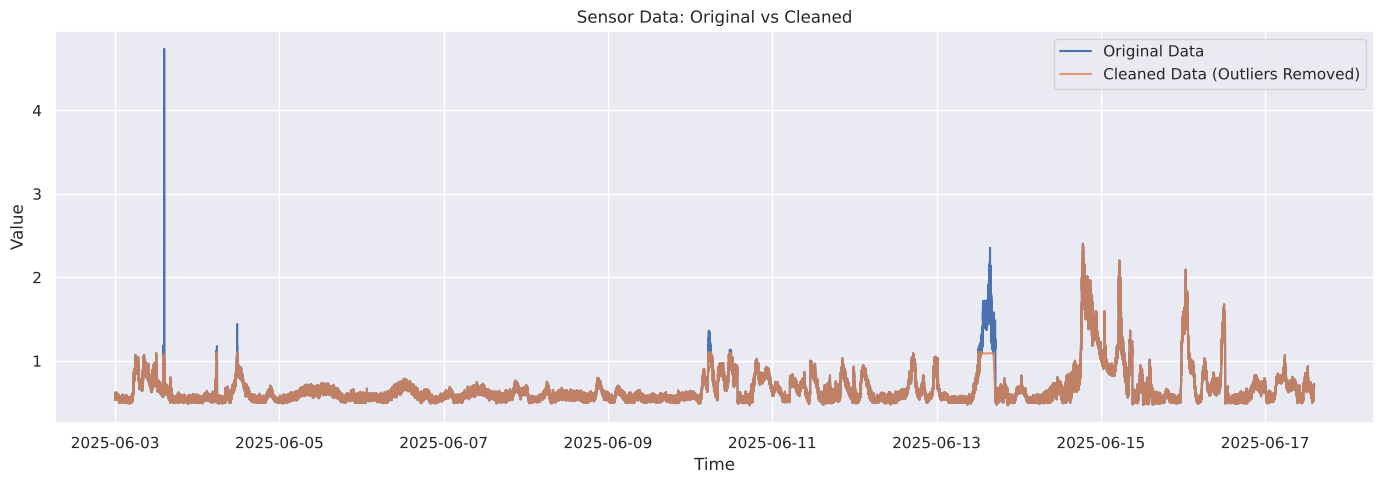

In [8]:
# ======================================
# PLOT ORIGINAL VS CLEANED SENSOR DATA
# ======================================

plt.figure(figsize=(14, 5))

# Plot original data with full range (including outliers)
plt.plot(df.index, df['value'], label='Original Data')

# Plot cleaned data (outliers removed)
plt.plot(df_clean.index, df_clean['value'], label='Cleaned Data (Outliers Removed)', alpha=0.8)

# Add title and axis labels
plt.title('Sensor Data: Original vs Cleaned')
plt.xlabel('Time')
plt.ylabel('Value')

# Show legend
plt.legend()

# Save plot to file
plt.tight_layout()
plt.savefig(FIG_DIR / "sensor_data_original_vs_cleaned.png", bbox_inches='tight')

# Display plot
plt.show()

In [9]:
# ======================================
# TRAIN-TEST SPLIT FOR ORIGINAL & CLEANED DATA
# ======================================

# -------- Original Data Split --------
train_orig = df.iloc[:split_index_orig]['value']  # Training set
test_orig = df.iloc[split_index_orig:]['value']   # Testing set

# -------- Cleaned Data Split --------
# Outliers are removed from the training part only; the cleaned test set is the original test set
train_clean = df['value'][is_train & keep]
test_clean = df['value'][~is_train]
assert test_clean.equals(test_orig)

# Print sizes of splits
print(f"Original train size: {len(train_orig)}, test size: {len(test_orig)}")
print(f"Cleaned train size: {len(train_clean)}, test size: {len(test_clean)}")
print(f"Last train timestamp {train_orig.index[-1]} < first test timestamp {test_orig.index[0]}: {train_orig.index[-1] < test_orig.index[0]}")

# -------- Naive baselines on the same test set --------
print("\nBaselines on the raw test set:")
base_raw = {
    "Persistence (last train value)": report("Persistence (last train value)", test_orig, np.full(len(test_orig), train_orig.iloc[-1])),
    "Train mean": report("Train mean", test_orig, np.full(len(test_orig), train_orig.mean())),
    "Persistence (cleaned train)": report("Persistence (last cleaned train value)", test_clean, np.full(len(test_clean), train_clean.iloc[-1])),
    "Train mean (cleaned train)": report("Train mean (cleaned train)", test_clean, np.full(len(test_clean), train_clean.mean())),
}

Original train size: 896940, test size: 224235
Cleaned train size: 880305, test size: 224235
Last train timestamp 2025-06-14 16:09:43.556662446+00:00 < first test timestamp 2025-06-14 16:09:44.603833706+00:00: True

Baselines on the raw test set:
Persistence (last train value)           RMSE: 0.3664  MAE: 0.2349
Train mean                               RMSE: 0.3922  MAE: 0.2420
Persistence (last cleaned train value)   RMSE: 0.3664  MAE: 0.2349
Train mean (cleaned train)               RMSE: 0.3995  MAE: 0.2457


                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:               896940
Model:               SARIMAX(0, 1, 0)   Log Likelihood             3173757.323
Date:                Mon, 26 Oct 2026   AIC                       -6347512.645
Time:                        18:07:04   BIC                       -6347500.939
Sample:                             0   HQIC                      -6347509.409
                             - 896940                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
sigma2      4.944e-05   3.65e-09   1.35e+04      0.000    4.94e-05    4.94e-05
Ljung-Box (L1) (Q):                   0.27   Jarque-Bera (JB):       24871877010.93
Prob(Q):                              0.60   Pr

ARIMA Original Data                      RMSE: 0.3664  MAE: 0.2349
Baseline: Persistence (last train value) RMSE: 0.3664  MAE: 0.2349
Baseline: Train mean                     RMSE: 0.3922  MAE: 0.2420


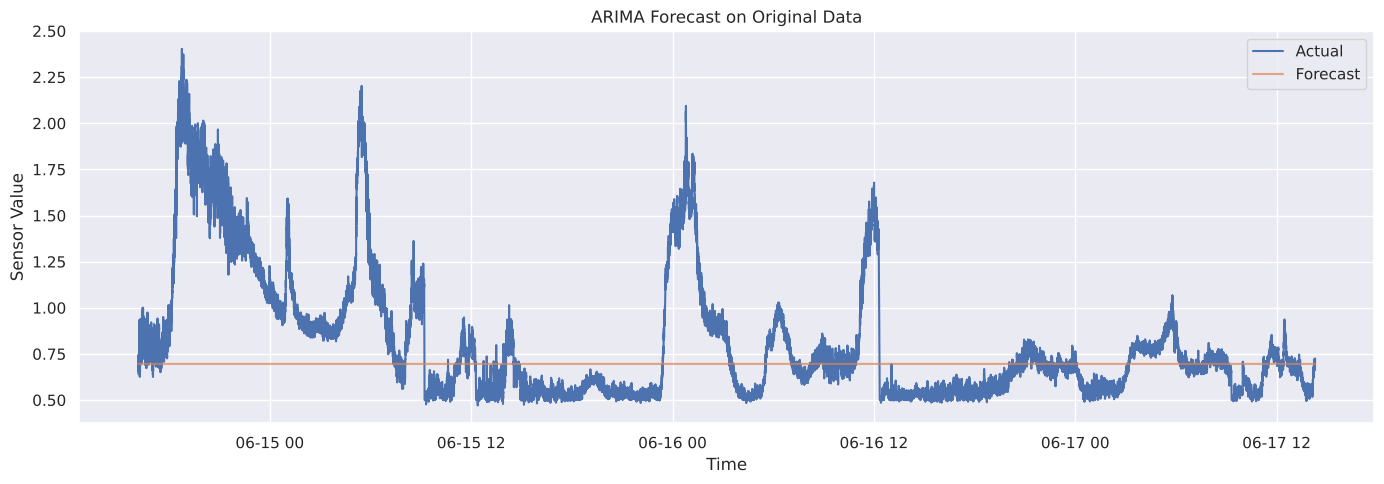

In [10]:
# ======================================
# FIT AUTO_ARIMA MODEL TO ORIGINAL TRAINING DATA
# ======================================

# Automatically find the best ARIMA (p,d,q) parameters
arima_model_orig = auto_arima(
    train_orig,
    seasonal=False,            # No seasonality
    stepwise=True,             # Use stepwise search for efficiency
    suppress_warnings=True     # Ignore convergence warnings
)

# Print model summary
print(arima_model_orig.summary())

# ======================================
# FORECAST & EVALUATE AUTO_ARIMA ON ORIGINAL DATA
# ======================================

# Forecast for the same number of periods as in the test set
forecast_orig = np.asarray(arima_model_orig.predict(n_periods=len(test_orig)))

# Evaluate the forecast using RMSE and MAE, next to the baselines on the same test set
rmse_orig, mae_orig = report("ARIMA Original Data", test_orig, forecast_orig)
for name in ("Persistence (last train value)", "Train mean"):
    print(f"{'Baseline: ' + name:<40} RMSE: {base_raw[name][0]:.4f}  MAE: {base_raw[name][1]:.4f}")


# ======================================
# PLOT ACTUAL VS FORECASTED VALUES FOR ORIGINAL DATA
# ======================================

plt.figure(figsize=(14, 5))

# Plot actual test data
plt.plot(test_orig.index, test_orig, label='Actual')

# Plot ARIMA forecasted values
plt.plot(test_orig.index, forecast_orig, label='Forecast', alpha=0.7)

# Add titles and labels
plt.title('ARIMA Forecast on Original Data')
plt.xlabel('Time')
plt.ylabel('Sensor Value')

# Show legend
plt.legend()

# Save plot to file
plt.tight_layout()
plt.savefig(FIG_DIR / "arima_forecast_original_data.png", bbox_inches='tight')

# Display plot
plt.show()

                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:               880305
Model:               SARIMAX(0, 1, 0)   Log Likelihood             3190337.741
Date:                Mon, 26 Oct 2026   AIC                       -6380673.482
Time:                        18:19:38   BIC                       -6380661.794
Sample:                             0   HQIC                      -6380670.249
                             - 880305                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
sigma2      4.165e-05   6.35e-09   6554.708      0.000    4.16e-05    4.17e-05
Ljung-Box (L1) (Q):                   0.00   Jarque-Bera (JB):        1369633202.56
Prob(Q):                              0.97   Pr

ARIMA Cleaned Data                       RMSE: 0.3664  MAE: 0.2349
Baseline: Persistence (cleaned train)    RMSE: 0.3664  MAE: 0.2349
Baseline: Train mean (cleaned train)     RMSE: 0.3995  MAE: 0.2457


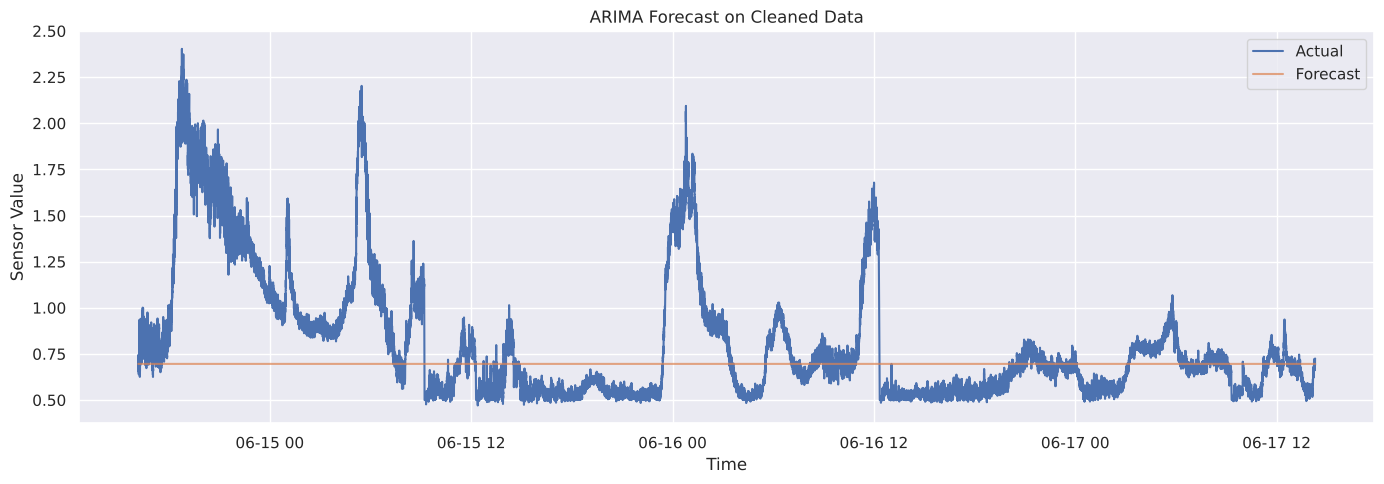

In [11]:
# ======================================
# FIT AUTO_ARIMA MODEL TO CLEANED TRAINING DATA
# ======================================
arima_model_clean = auto_arima(
    train_clean,
    seasonal=False,
    stepwise=True,
    suppress_warnings=True
)

# Print model summary
print(arima_model_clean.summary())

# ======================================
# FORECAST & EVALUATE ON CLEANED TEST DATA
# ======================================
forecast_clean = np.asarray(arima_model_clean.predict(n_periods=len(test_clean)))

rmse_clean, mae_clean = report("ARIMA Cleaned Data", test_clean, forecast_clean)
for name in ("Persistence (cleaned train)", "Train mean (cleaned train)"):
    print(f"{'Baseline: ' + name:<40} RMSE: {base_raw[name][0]:.4f}  MAE: {base_raw[name][1]:.4f}")

# ======================================
# PLOT ACTUAL VS FORECASTED VALUES (CLEANED DATA)
# ======================================
plt.figure(figsize=(14, 5))
plt.plot(test_clean.index, test_clean, label='Actual')
plt.plot(test_clean.index, forecast_clean, label='Forecast', alpha=0.7)
plt.title('ARIMA Forecast on Cleaned Data')
plt.xlabel('Time')
plt.ylabel('Sensor Value')
plt.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "arima_forecast_cleaned_data.png", bbox_inches='tight')  # Save plot
plt.show()

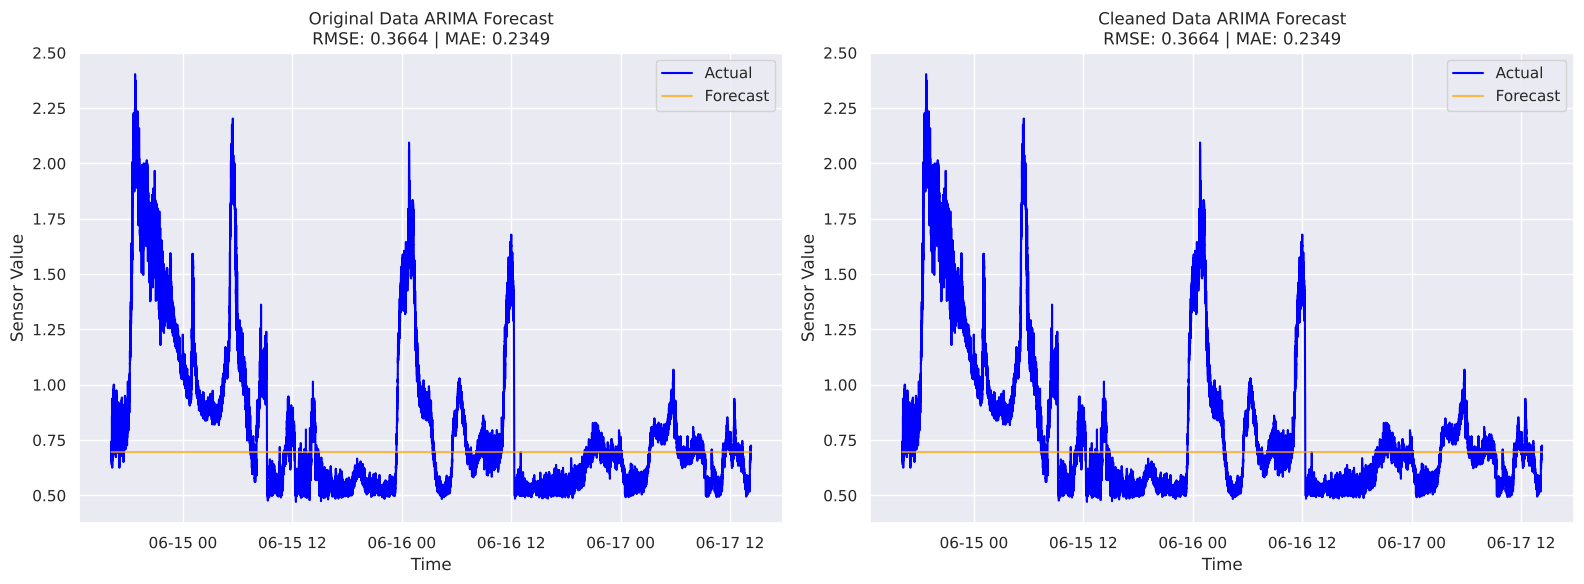

=== ARIMA Model Comparison ===
Original Data -> RMSE: 0.3664, MAE: 0.2349
Cleaned Data  -> RMSE: 0.3664, MAE: 0.2349


In [12]:
# ======================================
# COMPARE ARIMA FORECASTS: ORIGINAL VS CLEANED DATA
# ======================================

# Combine actual and forecasts for easier plotting

plt.figure(figsize=(16, 6))

# Plot Original Data Forecast
plt.subplot(1, 2, 1)
plt.plot(test_orig.index, test_orig, label='Actual', color='blue')
plt.plot(test_orig.index, forecast_orig, label='Forecast', alpha=0.7, color='orange')
plt.title(f'Original Data ARIMA Forecast\nRMSE: {rmse_orig:.4f} | MAE: {mae_orig:.4f}')
plt.xlabel('Time')
plt.ylabel('Sensor Value')
plt.legend()

# Plot Cleaned Data Forecast
plt.subplot(1, 2, 2)
plt.plot(test_clean.index, test_clean, label='Actual', color='blue')
plt.plot(test_clean.index, forecast_clean, label='Forecast', alpha=0.7, color='orange')
plt.title(f'Cleaned Data ARIMA Forecast\nRMSE: {rmse_clean:.4f} | MAE: {mae_clean:.4f}')
plt.xlabel('Time')
plt.ylabel('Sensor Value')
plt.legend()

plt.tight_layout()
plt.savefig(FIG_DIR / "arima_forecast_comparison.png", bbox_inches='tight')
plt.show()

# Optional: Print summary comparison
print("=== ARIMA Model Comparison ===")
print(f"Original Data -> RMSE: {rmse_orig:.4f}, MAE: {mae_orig:.4f}")
print(f"Cleaned Data  -> RMSE: {rmse_clean:.4f}, MAE: {mae_clean:.4f}")

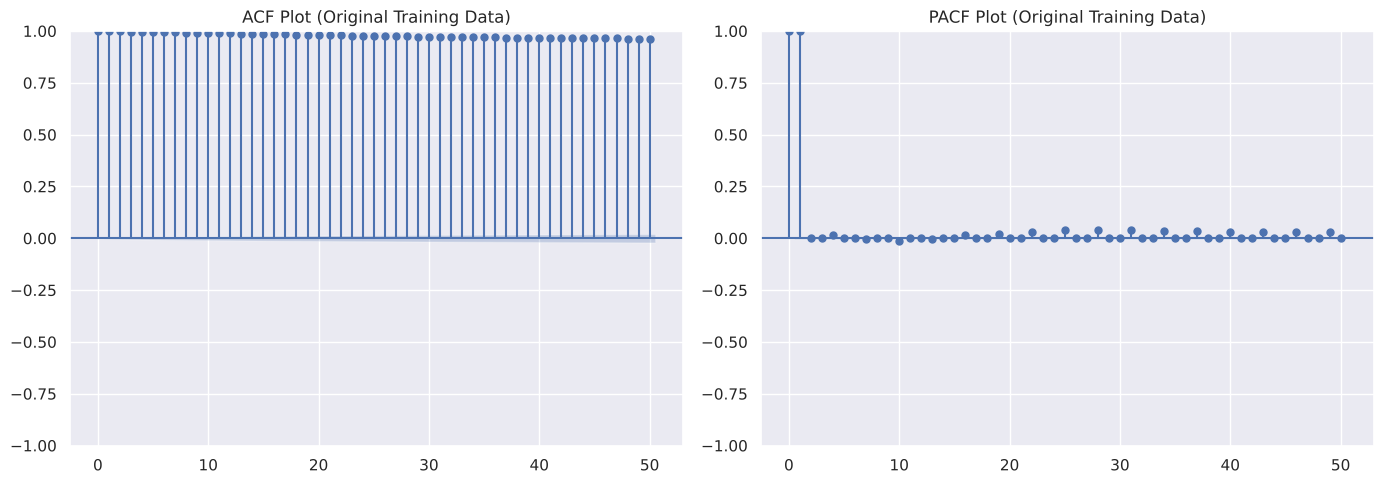

In [13]:
# ======================================
# ACF and PACF PLOTS FOR ORIGINAL TRAINING DATA
# ======================================
plt.figure(figsize=(14, 5))

# Plot ACF of original training data
plt.subplot(1, 2, 1)
plot_acf(train_orig, lags=50, ax=plt.gca())
plt.title('ACF Plot (Original Training Data)')

# Plot PACF of original training data
plt.subplot(1, 2, 2)
plot_pacf(train_orig, lags=50, ax=plt.gca(), method='ywm')
plt.title('PACF Plot (Original Training Data)')

plt.tight_layout()
plt.savefig(FIG_DIR / "acf_pacf_original_train.png", bbox_inches='tight')
plt.show()

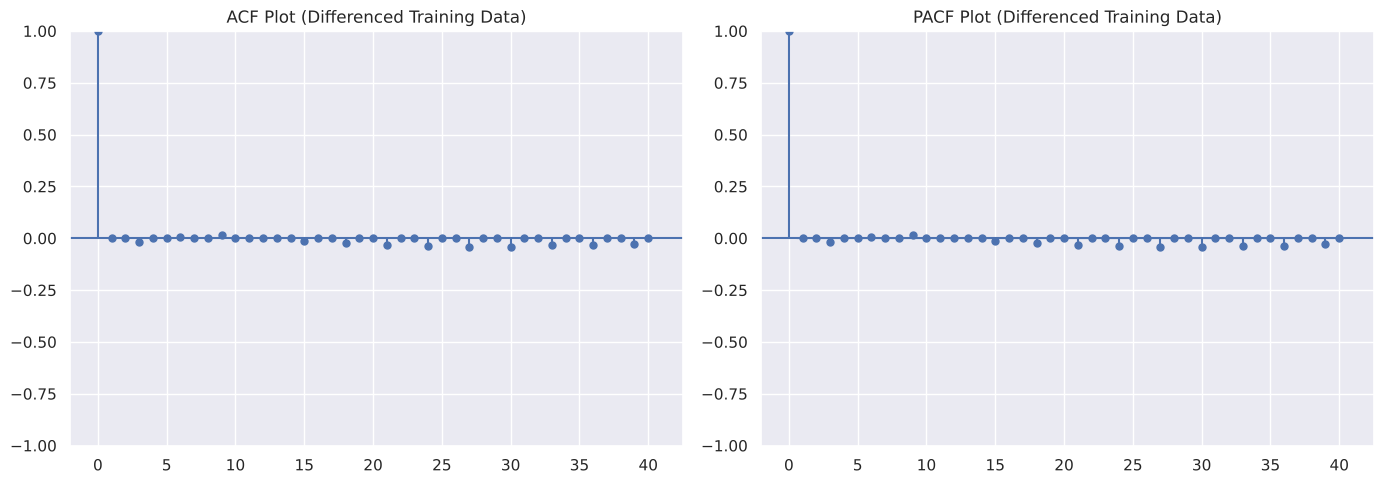

In [14]:
# ======================================
# DIFFERENCE THE TRAINING SERIES TO REMOVE TREND (d=1)
# ======================================
diff_train = train_orig.diff().dropna()

# ======================================
# ACF and PACF PLOTS FOR DIFFERENCED TRAINING DATA
# ======================================
plt.figure(figsize=(14, 5))

# Plot ACF of differenced training data
plt.subplot(1, 2, 1)
plot_acf(diff_train, lags=40, ax=plt.gca())
plt.title('ACF Plot (Differenced Training Data)')

# Plot PACF of differenced training data
plt.subplot(1, 2, 2)
plot_pacf(diff_train, lags=40, ax=plt.gca(), method='ywm')
plt.title('PACF Plot (Differenced Training Data)')

plt.tight_layout()
plt.savefig(FIG_DIR / "acf_pacf_differenced_train.png", bbox_inches='tight')
plt.show()

In [15]:
# ======================================
# COMPARE SEVERAL ARIMA MODELS ON ORIGINAL DATA
# ======================================
models = {
    'ARIMA(1,1,0)': (1, 1, 0),
    'ARIMA(0,1,1)': (0, 1, 1),
    'ARIMA(1,1,1)': (1, 1, 1)
}

results = {}

for name, order in models.items():
    model = ARIMA(train_orig, order=order)
    model_fit = model.fit()
    pred = model_fit.forecast(steps=len(test_orig))
    rmse = root_mean_squared_error(test_orig, np.asarray(pred))
    mae = mean_absolute_error(test_orig, np.asarray(pred))
    results[name] = {'RMSE': rmse, 'MAE': mae}
    print(f"{name} -> RMSE: {rmse:.4f}, MAE: {mae:.4f}")
for name in ("Persistence (last train value)", "Train mean"):
    print(f"Baseline: {name} -> RMSE: {base_raw[name][0]:.4f}, MAE: {base_raw[name][1]:.4f}")

ARIMA(1,1,0) -> RMSE: 0.3664, MAE: 0.2349


ARIMA(0,1,1) -> RMSE: 0.3664, MAE: 0.2349


ARIMA(1,1,1) -> RMSE: 0.3664, MAE: 0.2349
Baseline: Persistence (last train value) -> RMSE: 0.3664, MAE: 0.2349
Baseline: Train mean -> RMSE: 0.3922, MAE: 0.2420


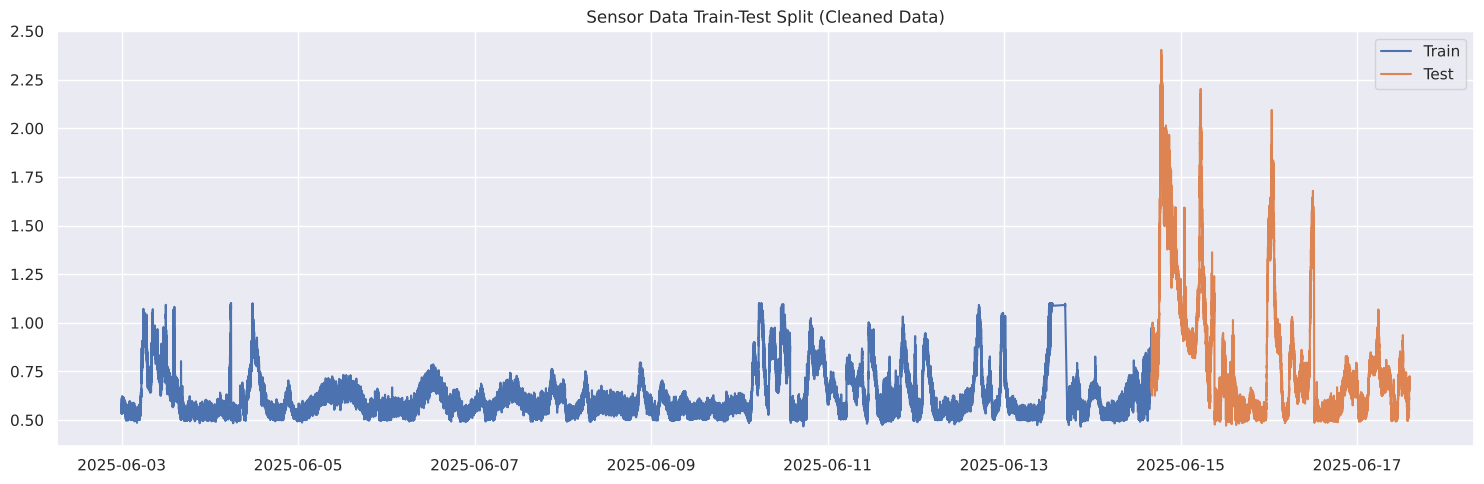

In [16]:
# ======================================
# TRAIN-TEST SPLIT ON CLEANED DATA
# ======================================
# Same split as above: training outliers removed, test set unchanged
train = train_clean
test = test_clean

plt.figure(figsize=(15, 5))
plt.plot(train, label='Train')
plt.plot(test, label='Test')
plt.title('Sensor Data Train-Test Split (Cleaned Data)')
plt.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "train_test_split_cleaned.png", bbox_inches='tight')
plt.show()

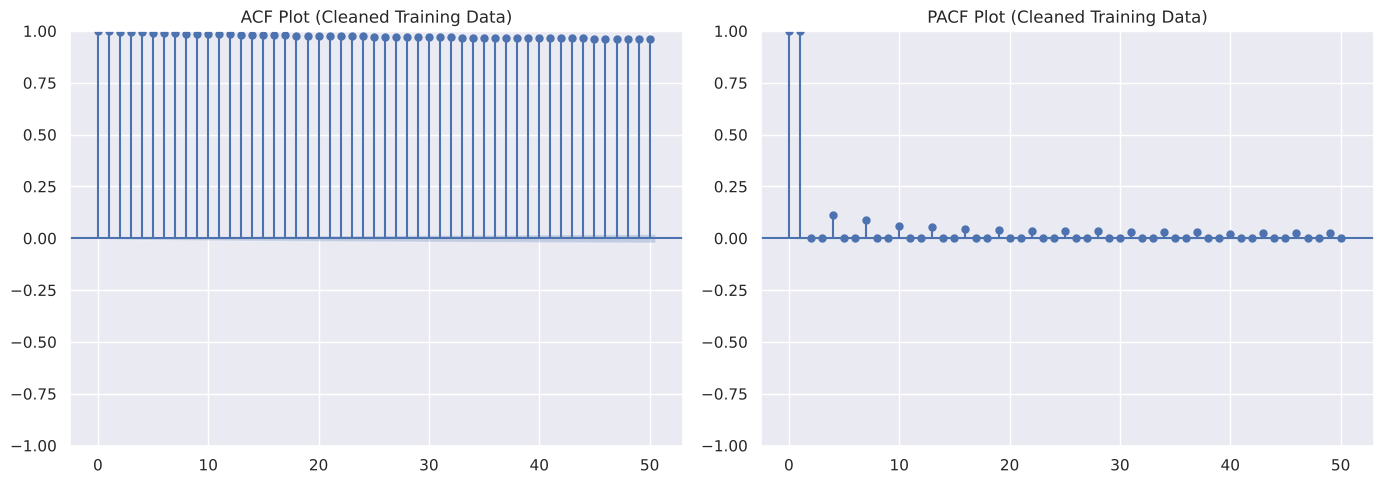

In [17]:
# ======================================
# ACF & PACF PLOTS ON CLEANED TRAINING DATA
# ======================================
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plot_acf(train, lags=50, ax=plt.gca())
plt.title('ACF Plot (Cleaned Training Data)')

plt.subplot(1, 2, 2)
plot_pacf(train, lags=50, ax=plt.gca(), method='ywm')
plt.title('PACF Plot (Cleaned Training Data)')

plt.tight_layout()
plt.savefig(FIG_DIR / "acf_pacf_cleaned_train.png", bbox_inches='tight')
plt.show()

In [18]:
# ======================================
# FIT ARIMA(1,1,1) ON CLEANED TRAINING DATA
# ======================================
model = sm.tsa.ARIMA(train, order=(1, 1, 1))
model_fit = model.fit()
print(model_fit.summary())

# Forecast on test set
forecast = np.asarray(model_fit.forecast(steps=len(test)))

                               SARIMAX Results                                
Dep. Variable:                  value   No. Observations:               880305
Model:                 ARIMA(1, 1, 1)   Log Likelihood             3190337.739
Date:                Mon, 26 Oct 2026   AIC                       -6380669.478
Time:                        18:33:03   BIC                       -6380634.413
Sample:                             0   HQIC                      -6380659.778
                             - 880305                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1       2.128e-16      0.006   3.82e-14      1.000      -0.011       0.011
ma.L1       1.693e-16      0.006   3.04e-14      1.000      -0.011       0.011
sigma2      4.165e-05   6.47e-09   6440.804      0.0

ETS Model                                RMSE: 0.3662  MAE: 0.2406


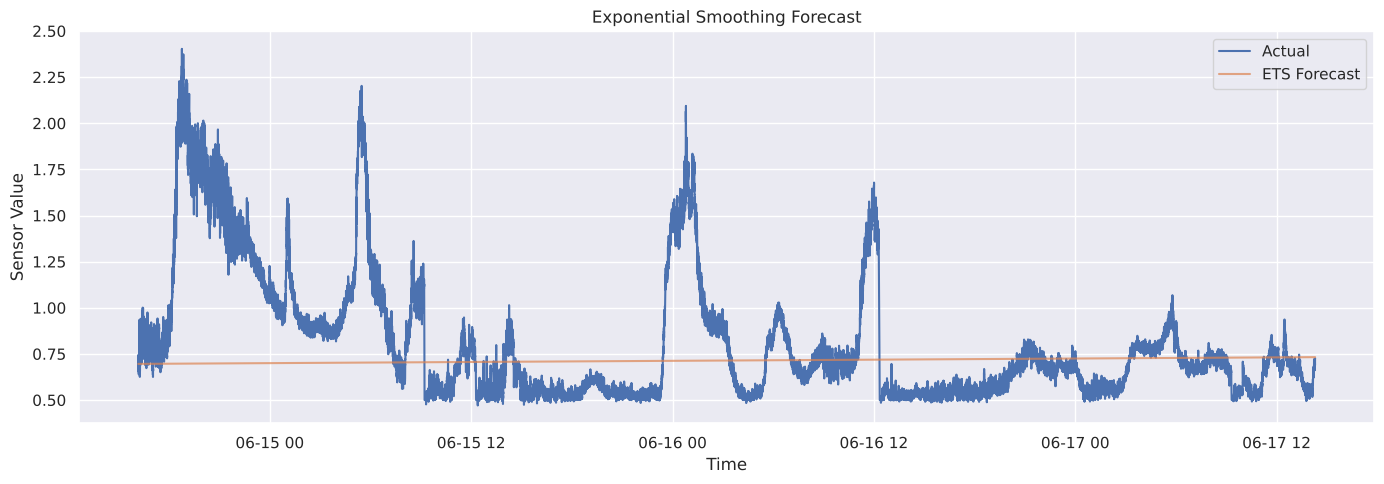

In [19]:
# ======================================
# FIT EXPONENTIAL SMOOTHING MODEL ON TRAINING DATA
# ======================================
ets_model = ExponentialSmoothing(train, trend='add', seasonal=None)
ets_fit = ets_model.fit()

# FORECAST ON TEST SET
ets_forecast = np.asarray(ets_fit.forecast(len(test)))

# ======================================
# EVALUATE THE ETS MODEL
# ======================================
rmse_ets, mae_ets = report("ETS Model", test, ets_forecast)

# ======================================
# PLOT ACTUAL VS FORECASTED VALUES
# ======================================
plt.figure(figsize=(14, 5))
plt.plot(test.index, test, label='Actual')
plt.plot(test.index, ets_forecast, label='ETS Forecast', alpha=0.7)
plt.title('Exponential Smoothing Forecast')
plt.xlabel('Time')
plt.ylabel('Sensor Value')
plt.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "ets_forecast.png", bbox_inches='tight')
plt.show()

ARIMA                                    RMSE: 0.3664  MAE: 0.2349
ETS                                      RMSE: 0.3662  MAE: 0.2406
Baseline: persistence (last train value) RMSE: 0.3664  MAE: 0.2349
Baseline: train mean                     RMSE: 0.3995  MAE: 0.2457


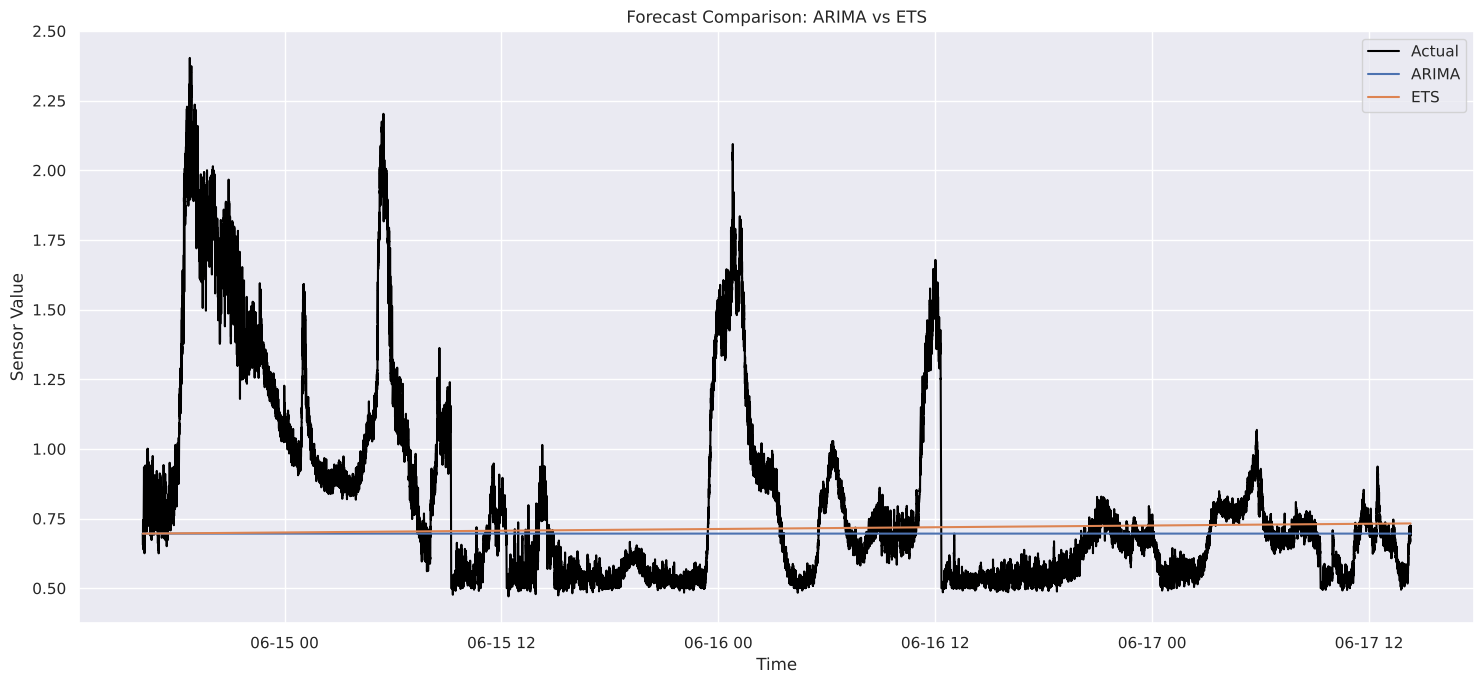

In [20]:
# ======================================
# EVALUATE MODELS NEXT TO THE BASELINES
# ======================================
rmse_arima, mae_arima = report("ARIMA", test, forecast)
rmse_ets, mae_ets = report("ETS", test, ets_forecast)
report("Baseline: persistence (last train value)", test, np.full(len(test), train.iloc[-1]))
report("Baseline: train mean", test, np.full(len(test), train.mean()))

# ======================================
# PLOT ACTUAL VS FORECASTED VALUES FOR BOTH MODELS
# ======================================
plt.figure(figsize=(15, 7))

plt.plot(test.index, test, label='Actual', color='black')
plt.plot(test.index, forecast, label='ARIMA')
plt.plot(test.index, ets_forecast, label='ETS')

plt.legend()
plt.title('Forecast Comparison: ARIMA vs ETS')
plt.xlabel('Time')
plt.ylabel('Sensor Value')
plt.tight_layout()
plt.savefig(FIG_DIR / "forecast_comparison_arima_ets.png", bbox_inches='tight')
plt.show()

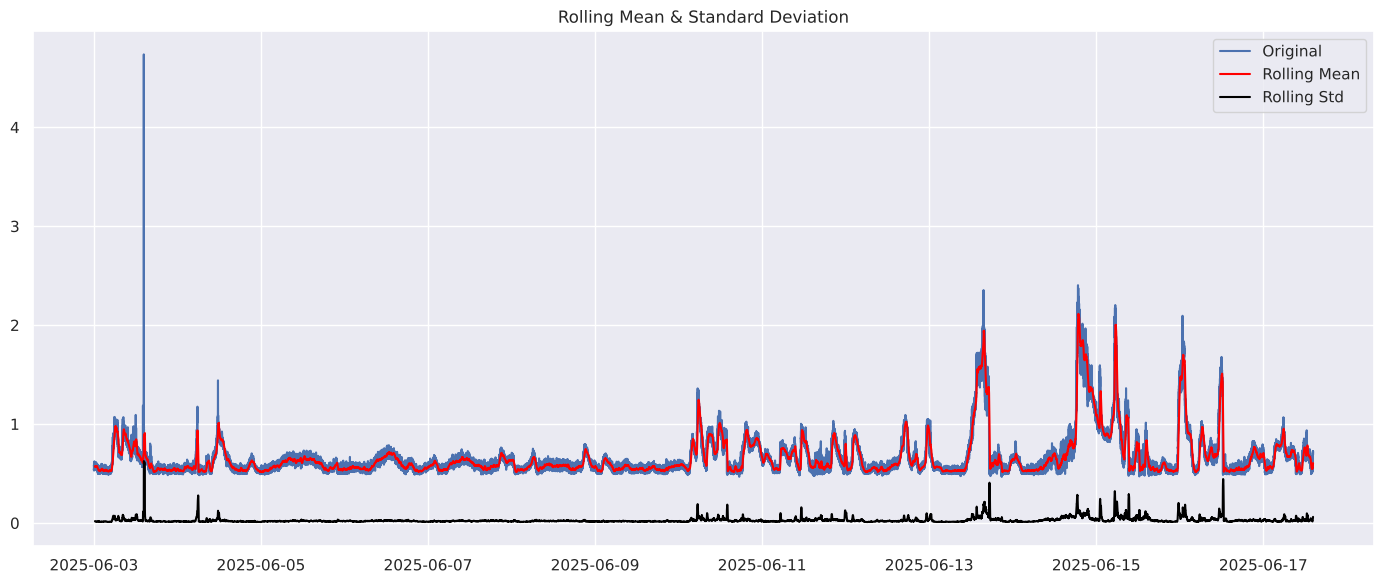

In [21]:
# ======================================
# PLOT ROLLING MEAN AND STANDARD DEVIATION
# ======================================
rolling_mean = df['value'].rolling(window=1000).mean()
rolling_std = df['value'].rolling(window=1000).std()

plt.figure(figsize=(14, 6))
plt.plot(df['value'], label='Original')
plt.plot(rolling_mean, label='Rolling Mean', color='red')
plt.plot(rolling_std, label='Rolling Std', color='black')
plt.legend()
plt.title("Rolling Mean & Standard Deviation")
plt.grid(True)

plt.tight_layout()
plt.savefig(FIG_DIR / "rolling_mean_std.png", bbox_inches='tight')
plt.show()

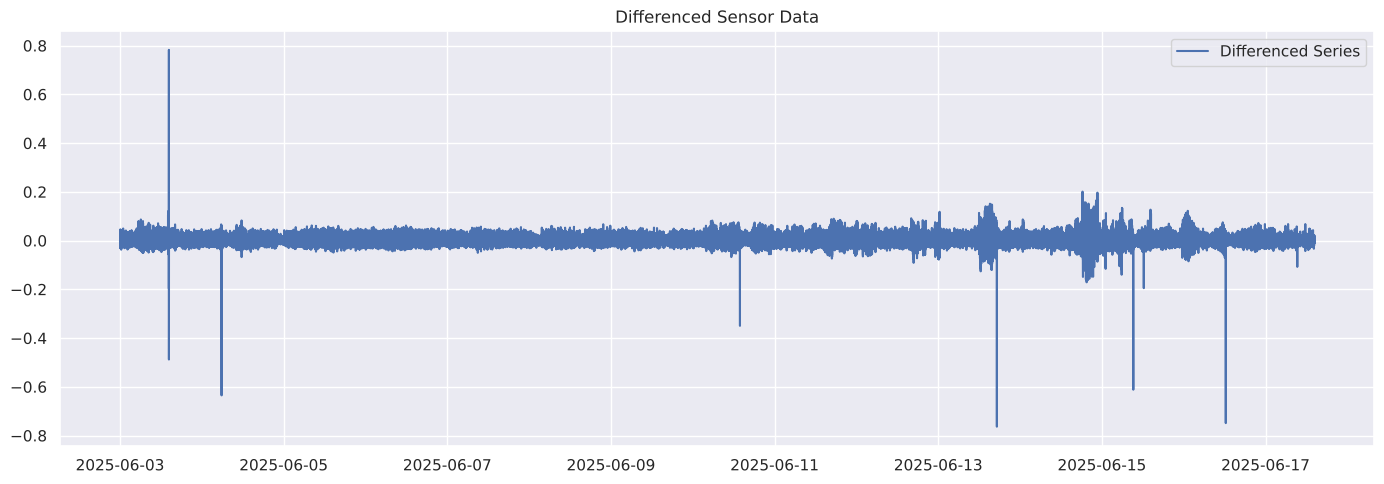

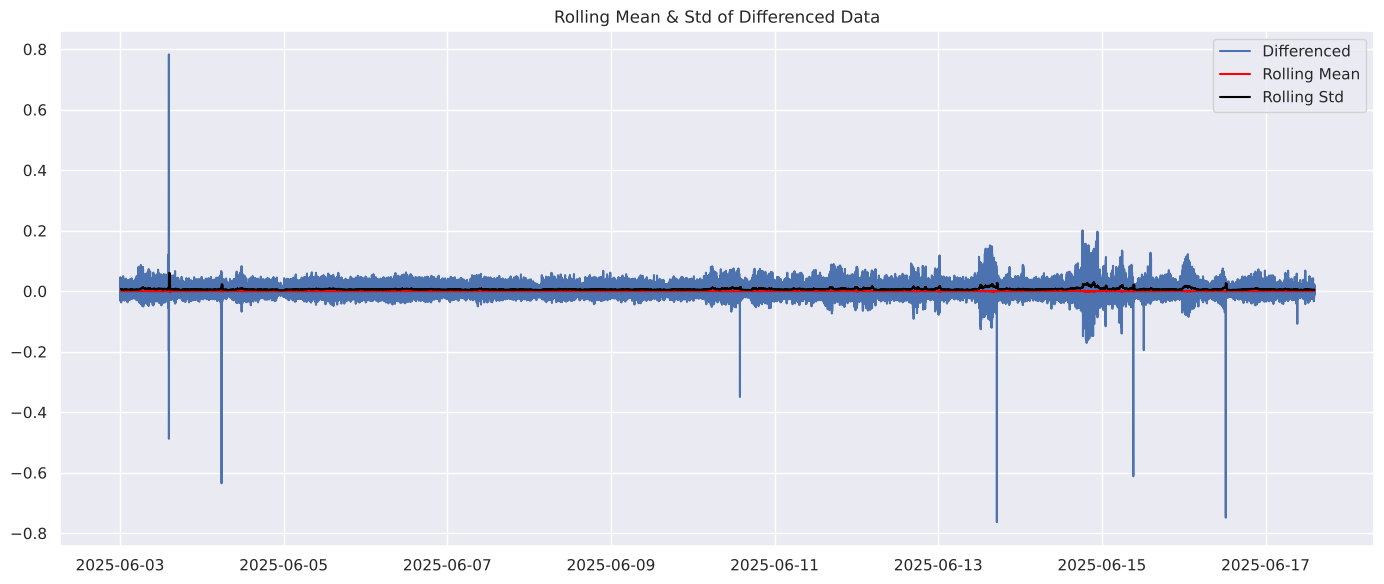

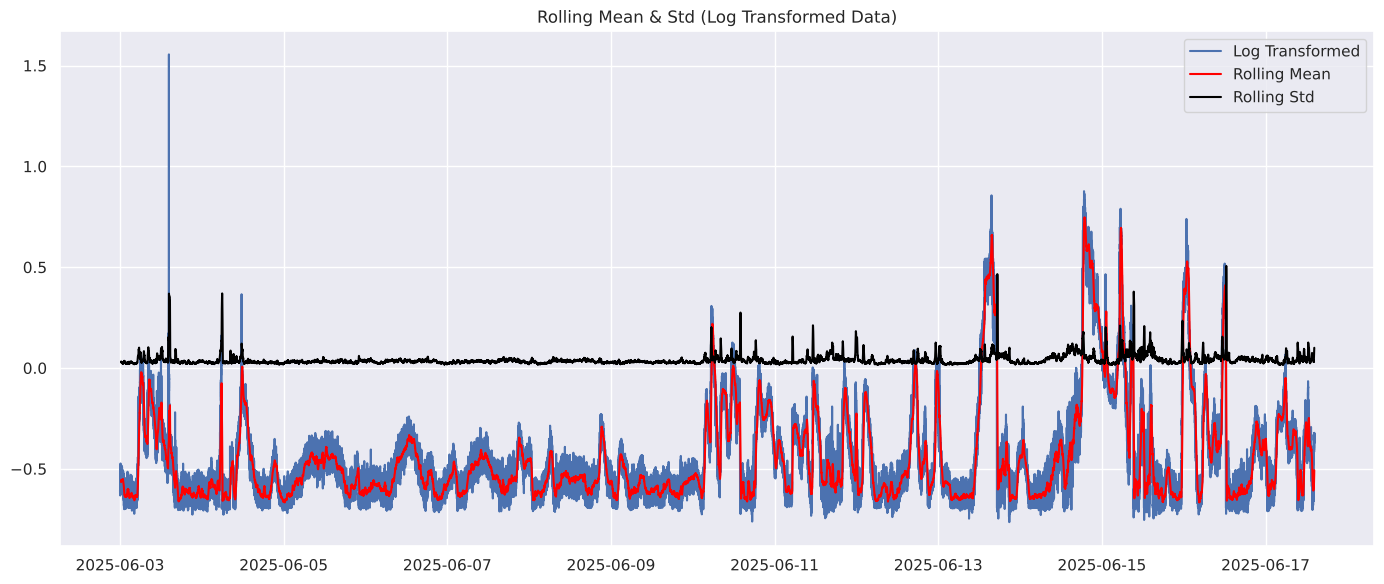

ADF Statistic: -15.780711965763096
p-value: 1.1320581957483338e-28
Lags used (search limited to 20): 18
Critical Values:
   1%: -3.43035583265395
   5%: -2.8615425779675414
   10%: -2.5667713721574033


In [22]:
# Memory: the fitted auto-ARIMA and ARIMA objects above hold copies of the 0.9 M training points.
# They are no longer needed (their forecasts are kept), so free them before the plots and the ADF test below.
import gc

del arima_model_orig, arima_model_clean, model, model_fit
gc.collect()

# ======================================
# DIFFERENCING THE SERIES TO REMOVE TREND
# ======================================
df_diff = df['value'].diff().dropna()

plt.figure(figsize=(14, 5))
plt.plot(df_diff, label='Differenced Series')
plt.title("Differenced Sensor Data")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "differenced_series.png", bbox_inches='tight')
plt.show()

# ======================================
# ROLLING MEAN & STD OF DIFFERENCED DATA
# ======================================
rolling_mean_diff = df_diff.rolling(window=1000).mean()
rolling_std_diff = df_diff.rolling(window=1000).std()

plt.figure(figsize=(14, 6))
plt.plot(df_diff, label='Differenced')
plt.plot(rolling_mean_diff, label='Rolling Mean', color='red')
plt.plot(rolling_std_diff, label='Rolling Std', color='black')
plt.legend()
plt.title("Rolling Mean & Std of Differenced Data")
plt.grid(True)
plt.tight_layout()
plt.savefig(FIG_DIR / "rolling_mean_std_differenced.png", bbox_inches='tight')
plt.show()

# ======================================
# LOG TRANSFORMATION TO STABILIZE VARIANCE
# ======================================
df_log = np.log(df['value'])

rolling_mean_log = df_log.rolling(window=1000).mean()
rolling_std_log = df_log.rolling(window=1000).std()

plt.figure(figsize=(14, 6))
plt.plot(df_log, label='Log Transformed')
plt.plot(rolling_mean_log, label='Rolling Mean', color='red')
plt.plot(rolling_std_log, label='Rolling Std', color='black')
plt.legend()
plt.title("Rolling Mean & Std (Log Transformed Data)")
plt.grid(True)
plt.tight_layout()
plt.savefig(FIG_DIR / "rolling_mean_std_log_transformed.png", bbox_inches='tight')
plt.show()

# ======================================
# AUGMENTED DICKEY-FULLER TEST ON LOG-TRANSFORMED DATA
# ======================================
# Reduced to fit in 16 GB: the lag search is limited to 20 lags (maxlag=20) instead of the
# statsmodels default for 1.1 M points (123 lags). autolag="AIC" still picks the best lag up to 20.
# With the default, this one test needs more than 14 GB on its own.
result = adfuller(df_log.dropna(), maxlag=20, autolag="AIC")
print("ADF Statistic:", result[0])
print("p-value:", result[1])
print("Lags used (search limited to 20):", result[2])
print("Critical Values:")
for key, value in result[4].items():
    print(f"   {key}: {value}")

In [23]:
# ======================================
# TRAIN-TEST SPLIT ON LOG-TRANSFORMED DATA (80%-20%)
# ======================================
df_log = np.log(df['value'])

train_size = int(len(df_log) * 0.8)
train_log, test_log = df_log[:train_size], df_log[train_size:]

ARIMA(1,0,1) on Log-Transformed Data
RMSE: 0.3984
MAE: 0.2450
Optimizer converged: True
Baseline: Persistence (last train value) RMSE: 0.3664  MAE: 0.2349
Baseline: Train mean RMSE: 0.3922  MAE: 0.2420


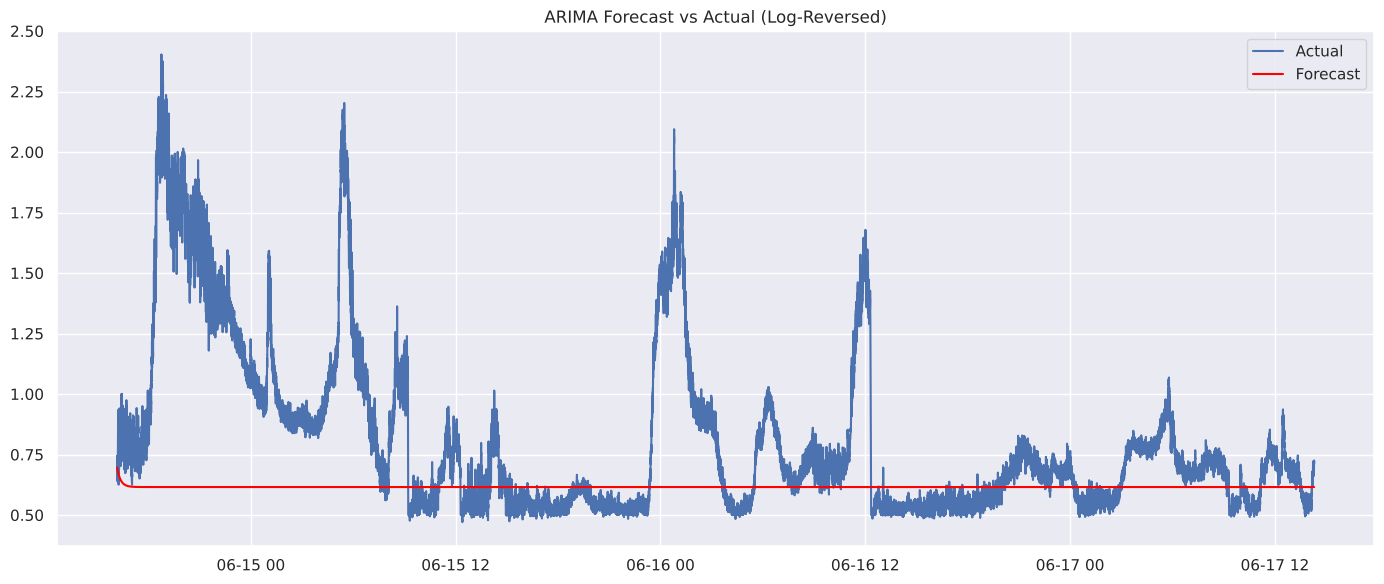

In [24]:
# ======================================
# FIT ARIMA(1,0,1) ON LOG-TRANSFORMED TRAIN DATA
# ======================================
model = ARIMA(train_log, order=(1, 0, 1))
model_fit = model.fit()

# FORECAST LOG-TRANSFORMED TEST PERIOD
forecast_log = np.asarray(model_fit.forecast(steps=len(test_log)))

# REVERSE LOG TRANSFORM TO ORIGINAL SCALE
forecast = np.exp(forecast_log)
actual = np.exp(test_log)

# EVALUATE MODEL PERFORMANCE
rmse = root_mean_squared_error(actual, forecast)
mae = mean_absolute_error(actual, forecast)

print("ARIMA(1,0,1) on Log-Transformed Data")
print(f"RMSE: {rmse:.4f}")
print(f"MAE: {mae:.4f}")
print(f"Optimizer converged: {model_fit.mle_retvals.get('converged')}")
for name in ("Persistence (last train value)", "Train mean"):
    print(f"Baseline: {name} RMSE: {base_raw[name][0]:.4f}  MAE: {base_raw[name][1]:.4f}")

# PLOT FORECAST VS ACTUAL
plt.figure(figsize=(14, 6))
plt.plot(actual.index, actual, label='Actual')
plt.plot(actual.index, forecast, label='Forecast', color='red')
plt.legend()
plt.title("ARIMA Forecast vs Actual (Log-Reversed)")
plt.grid(True)
plt.tight_layout()
plt.savefig(FIG_DIR / "arima_log_reversed_forecast.png", bbox_inches='tight')
plt.show()

In [25]:
# ======================================
# FIT ARIMA(3,0,3) ON LOG-TRANSFORMED TRAIN DATA
# ======================================
model = ARIMA(train_log, order=(3, 0, 3))
model_fit = model.fit()

forecast_log = np.asarray(model_fit.forecast(steps=len(test_log)))

forecast = np.exp(forecast_log)
actual = np.exp(test_log)

rmse = root_mean_squared_error(actual, forecast)
mae = mean_absolute_error(actual, forecast)

print("ARIMA(3,0,3) on Log-Transformed Data")
print(f"RMSE: {rmse:.4f}")
print(f"MAE: {mae:.4f}")
print(f"Optimizer converged: {model_fit.mle_retvals.get('converged')}")
for name in ("Persistence (last train value)", "Train mean"):
    print(f"Baseline: {name} RMSE: {base_raw[name][0]:.4f}  MAE: {base_raw[name][1]:.4f}")
print("Result: implausible, not used (a fixed-order ARIMA forecast over the whole 2.9-day test set is not a credible model result).")

ARIMA(3,0,3) on Log-Transformed Data
RMSE: 0.3984
MAE: 0.2449
Optimizer converged: True
Baseline: Persistence (last train value) RMSE: 0.3664  MAE: 0.2349
Baseline: Train mean RMSE: 0.3922  MAE: 0.2420
Result: implausible, not used (a fixed-order ARIMA forecast over the whole 2.9-day test set is not a credible model result).


In [26]:
# ======================================
# EXPONENTIAL SMOOTHING (ETS) MODEL ON ORIGINAL TRAIN DATA
# ======================================
model_ets = ExponentialSmoothing(train_orig, trend='add', seasonal=None)
model_fit_ets = model_ets.fit()

forecast_ets = np.asarray(model_fit_ets.forecast(len(test_orig)))

rmse_ets = root_mean_squared_error(test_orig, forecast_ets)
mae_ets = mean_absolute_error(test_orig, forecast_ets)

print("ETS Model on Original Data")
print(f"RMSE: {rmse_ets:.4f}")
print(f"MAE: {mae_ets:.4f}")
for name in ("Persistence (last train value)", "Train mean"):
    print(f"Baseline: {name} RMSE: {base_raw[name][0]:.4f}  MAE: {base_raw[name][1]:.4f}")

ETS Model on Original Data
RMSE: 0.3662
MAE: 0.2405
Baseline: Persistence (last train value) RMSE: 0.3664  MAE: 0.2349
Baseline: Train mean RMSE: 0.3922  MAE: 0.2420


Missing 1-minute intervals: 2


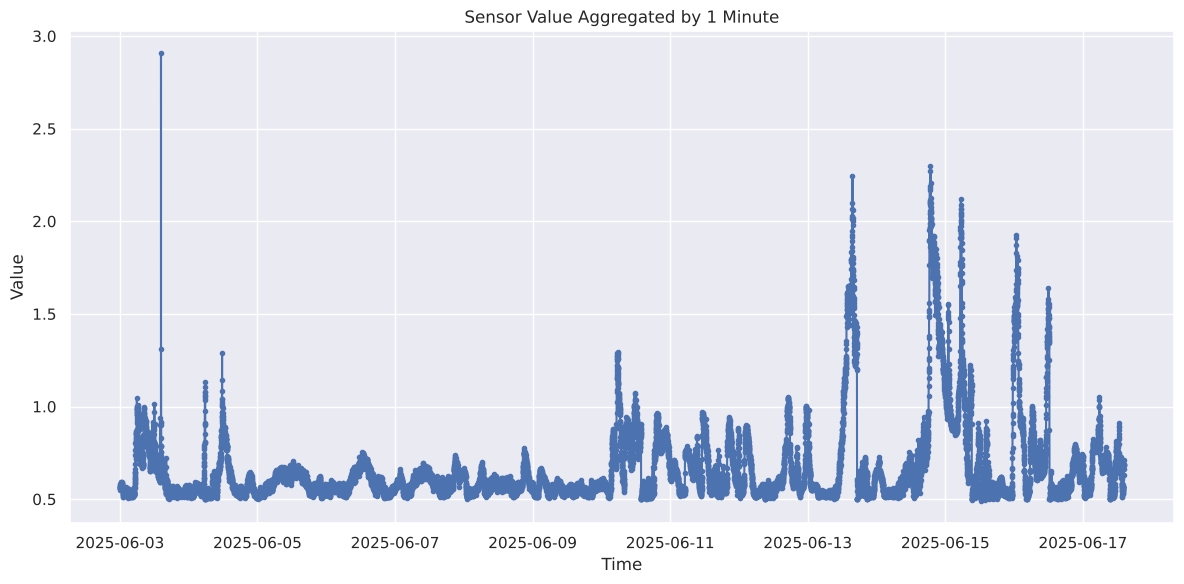

In [27]:
# ======================================
# RESAMPLE DATA TO 1-MINUTE INTERVALS (MEAN AGGREGATION)
# ======================================
df_1min = df['value'].resample('1min').mean()

# CHECK MISSING MINUTES
missing = df_1min.isna().sum()
print(f"Missing 1-minute intervals: {missing}")

# Regular 1-minute grid: fill the empty minutes by time interpolation
df_1min = df_1min.asfreq('1min').interpolate(method='time')

# PLOT RESAMPLED TIME SERIES
plt.figure(figsize=(12, 6))
plt.plot(df_1min, marker='.', linestyle='-')
plt.title('Sensor Value Aggregated by 1 Minute')
plt.xlabel('Time')
plt.ylabel('Value')
plt.grid(True)
plt.tight_layout()
plt.savefig(FIG_DIR / "resampled_1min_timeseries.png", bbox_inches='tight')
plt.show()

Number of outliers detected: 965
  in the training part (replaced by interpolation): 315
  in the test part (kept, test points are never dropped): 650


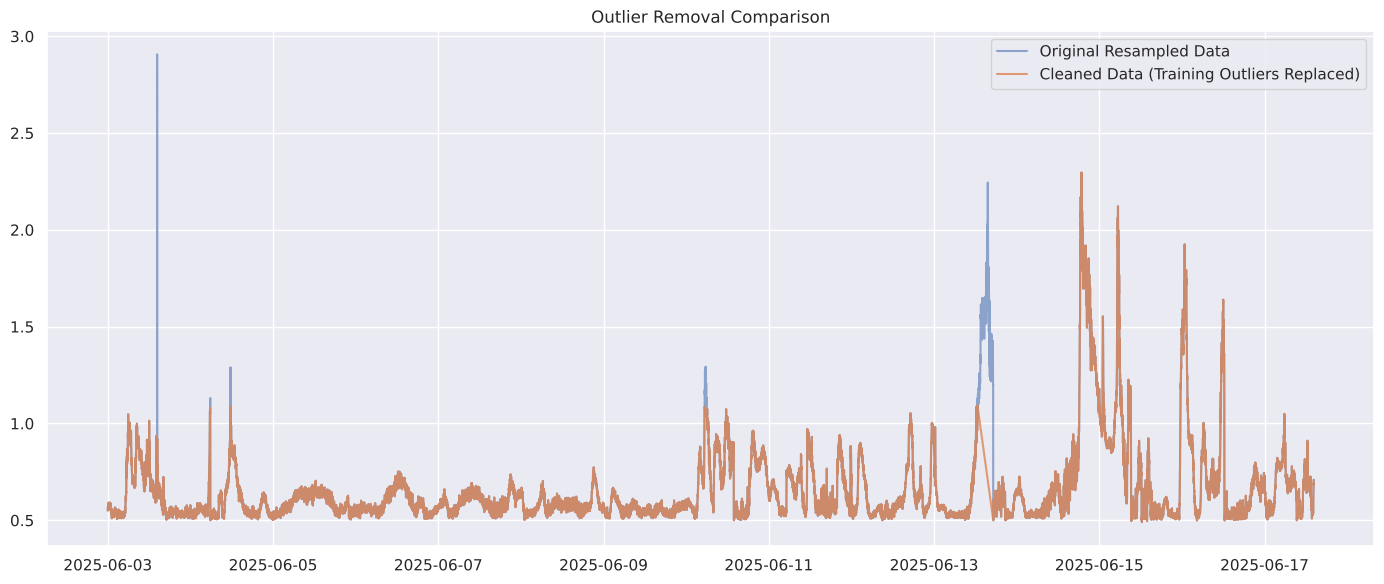

In [28]:
# ======================================
# OUTLIER DETECTION USING Z-SCORE ON RESAMPLED DATA (LIMITS FROM THE TRAINING PART ONLY)
# ======================================
split_1min = int(len(df_1min) * 0.8)
is_train_1min = np.arange(len(df_1min)) < split_1min
mu_1min = df_1min.iloc[:split_1min].mean()
sd_1min = df_1min.iloc[:split_1min].std()
z_1min = (df_1min - mu_1min) / sd_1min

# IDENTIFY OUTLIERS: abs(z_score) > 3
is_outlier = np.abs(z_1min) > 3
print(f"Number of outliers detected: {int(is_outlier.sum())}")
print(f"  in the training part (replaced by interpolation): {int((is_outlier & is_train_1min).sum())}")
print(f"  in the test part (kept, test points are never dropped): {int((is_outlier & ~is_train_1min).sum())}")

# Training outliers are replaced by time interpolation so the series stays on the 1-minute grid
df_clean = df_1min.mask(is_outlier & is_train_1min).interpolate(method='time')

# PLOT ORIGINAL VS CLEANED DATA
plt.figure(figsize=(14, 6))
plt.plot(df_1min, label='Original Resampled Data', alpha=0.6)
plt.plot(df_clean, label='Cleaned Data (Training Outliers Replaced)', alpha=0.8)
plt.legend()
plt.title('Outlier Removal Comparison')
plt.grid(True)
plt.tight_layout()
plt.savefig(FIG_DIR / "outlier_removal_comparison.png", bbox_inches='tight')
plt.show()

ADF Statistic: -7.931651492491442
p-value: 3.5000905457690307e-12
Critical Values:
   1%: -3.4306618342889883
   5%: -2.8616778201482687
   10%: -2.5668433578378917
Train 16814 minutes, test 4204 minutes; last train 2025-06-14 16:13:00+00:00 < first test 2025-06-14 16:14:00+00:00: True


ARIMA(1,1,1)                             RMSE: 0.3478  MAE: 0.2583


ETS (additive trend)                     RMSE: 0.3624  MAE: 0.2894


18:45:46 - cmdstanpy - INFO - Chain [1] start processing


18:45:58 - cmdstanpy - INFO - Chain [1] done processing


Prophet                                  RMSE: 0.4091  MAE: 0.2533
Baseline: SMA(5)                         RMSE: 0.3536  MAE: 0.2403
Baseline: persistence (last train value) RMSE: 0.3516  MAE: 0.2770
Baseline: train mean                     RMSE: 0.3968  MAE: 0.2445


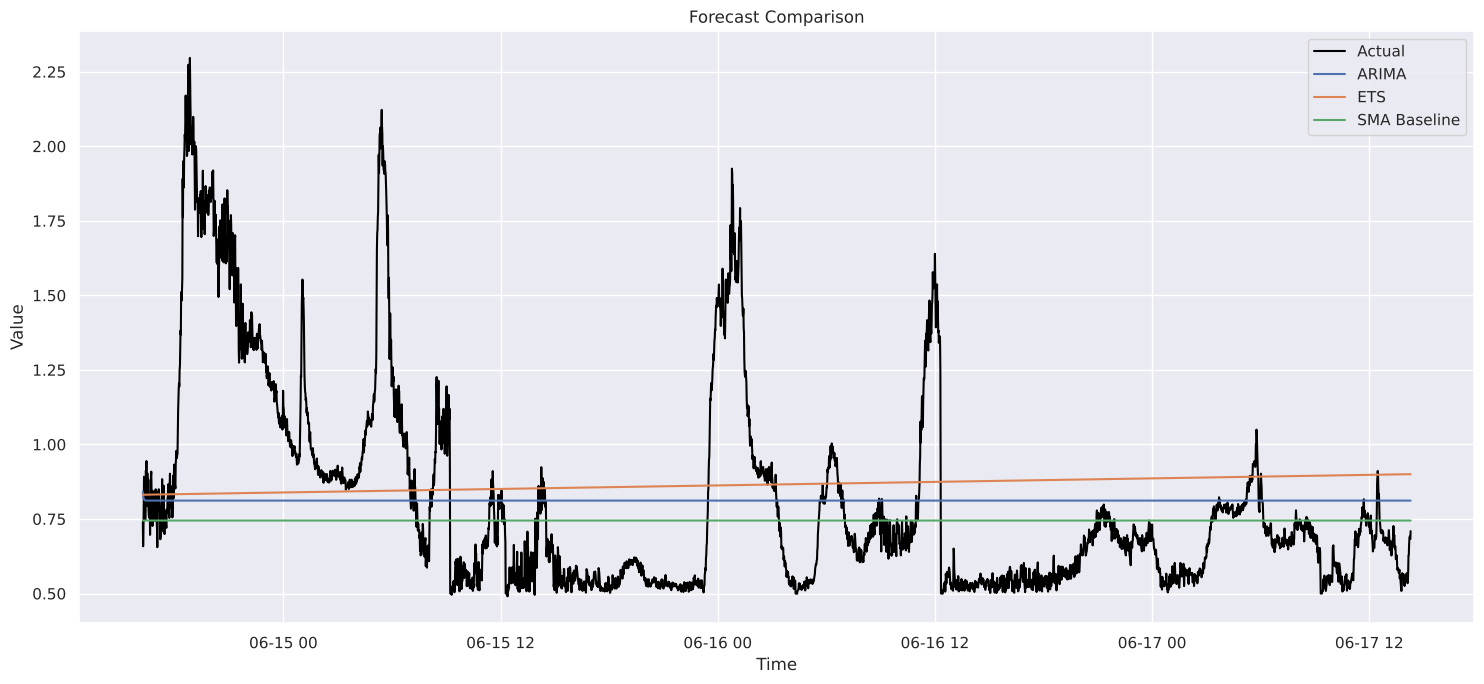

Train data stats:
count    16814.000000
mean         0.617499
std          0.109297
min          0.500000
25%          0.543242
50%          0.577884
75%          0.648387
max          1.092962
Name: value, dtype: float64


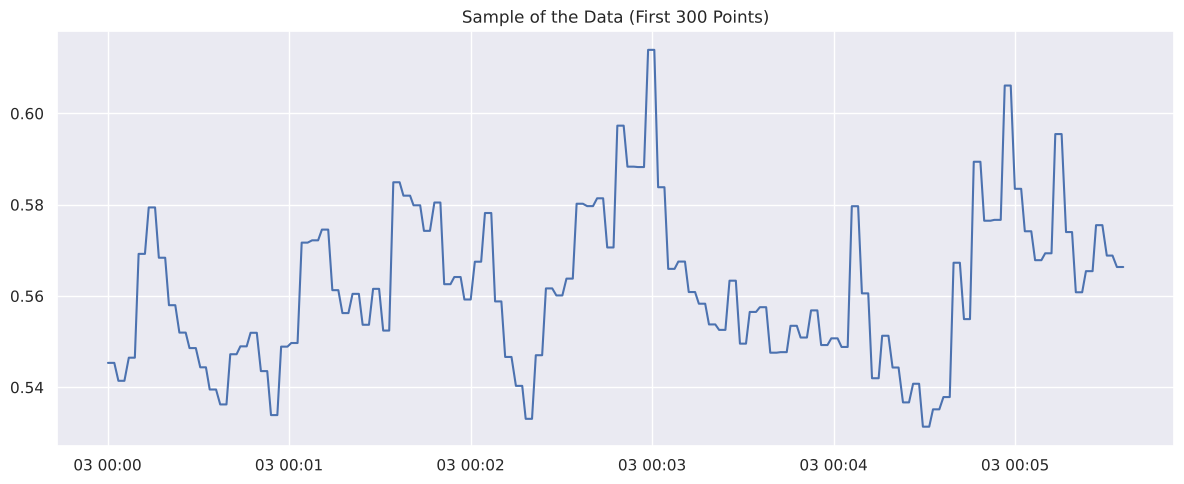

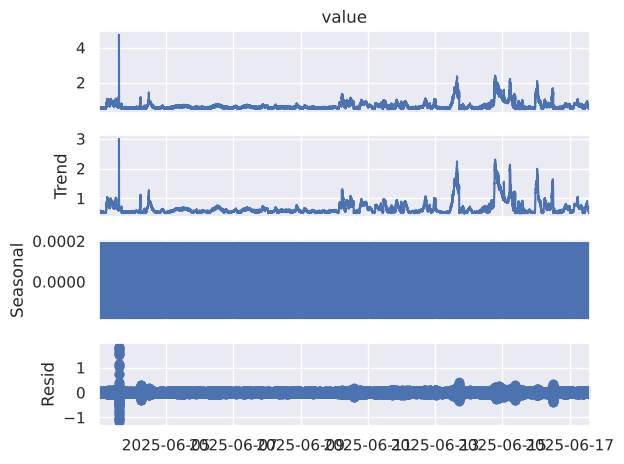

In [29]:
# ============================
# AUGMENTED DICKEY-FULLER TEST TO CHECK STATIONARITY
# ============================
result = adfuller(df_clean.dropna())
print('ADF Statistic:', result[0])
print('p-value:', result[1])
print('Critical Values:')
for key, value in result[4].items():
    print(f'   {key}: {value}')

# ============================
# TRAIN-TEST SPLIT (80-20)
# ============================
train = df_clean.iloc[:split_1min]
test = df_clean.iloc[split_1min:]
print(f"Train {len(train)} minutes, test {len(test)} minutes; last train {train.index[-1]} < first test {test.index[0]}: {train.index[-1] < test.index[0]}")

# ============================
# ARIMA MODEL FITTING AND FORECASTING
# ============================
model_arima = ARIMA(train, order=(1,1,1))
model_arima_fit = model_arima.fit()
forecast_arima = np.asarray(model_arima_fit.forecast(steps=len(test)))

rmse_arima, mae_arima = report('ARIMA(1,1,1)', test, forecast_arima)

# ============================
# ETS MODEL FITTING AND FORECASTING
# ============================
model_ets = ExponentialSmoothing(train, trend='add', seasonal=None)
model_ets_fit = model_ets.fit()
forecast_ets = np.asarray(model_ets_fit.forecast(len(test)))

rmse_ets, mae_ets = report('ETS (additive trend)', test, forecast_ets)

# ============================
# PROPHET MODEL FITTING AND FORECASTING
# ============================
df_prophet = train.reset_index().rename(columns={'time': 'ds', 'value': 'y'})
df_prophet['ds'] = pd.to_datetime(df_prophet['ds']).dt.tz_localize(None)

model_prophet = Prophet()
model_prophet.fit(df_prophet)

future = model_prophet.make_future_dataframe(periods=len(test), freq='min')
forecast_prophet = model_prophet.predict(future)

forecast_values = forecast_prophet['yhat'][-len(test):].values

rmse_prophet, mae_prophet = report('Prophet', test, forecast_values)

# ============================
# SIMPLE MOVING AVERAGE (SMA) BASELINE FORECAST
# ============================
window_size = 5
sma_forecast = train.rolling(window=window_size).mean().iloc[-1]
sma_forecast_values = np.repeat(sma_forecast, len(test))

rmse_sma, mae_sma = report('Baseline: SMA(5)', test, sma_forecast_values)

# ============================
# MORE NAIVE BASELINES ON THE SAME TEST SET
# ============================
report('Baseline: persistence (last train value)', test, np.full(len(test), train.iloc[-1]))
report('Baseline: train mean', test, np.full(len(test), train.mean()))

# ============================
# PLOT FORECAST COMPARISON
# ============================
plt.figure(figsize=(15, 7))
plt.plot(test.index, test, label='Actual', color='black')
plt.plot(test.index, forecast_arima, label='ARIMA')
plt.plot(test.index, forecast_ets, label='ETS')
# Uncomment the next line to plot Prophet forecast as well
# plt.plot(test.index, forecast_values, label='Prophet')
plt.plot(test.index, sma_forecast_values, label='SMA Baseline')
plt.legend()
plt.title('Forecast Comparison')
plt.xlabel('Time')
plt.ylabel('Value')
plt.grid(True)
plt.tight_layout()
plt.savefig(FIG_DIR / "voc_forecasts_vs_sma_baseline.png", bbox_inches='tight')
plt.show()

# ============================
# TRAIN DATA STATISTICS
# ============================
print("Train data stats:")
print(train.describe())

# ============================
# PLOT SAMPLE OF RAW DATA (FIRST 300 POINTS)
# ============================
plt.figure(figsize=(12, 5))
plt.plot(df['value'][:300])
plt.title('Sample of the Data (First 300 Points)')
plt.grid(True)
plt.tight_layout()
plt.savefig(FIG_DIR / "sample_data_300points.png", bbox_inches='tight')
plt.show()

# ============================
# SEASONAL DECOMPOSITION PLOT (Additive Model)
# ============================
result = seasonal_decompose(df['value'], model='additive', period=60)  # Adjust period if needed
result.plot()
plt.tight_layout()
plt.savefig(FIG_DIR / "seasonal_decompose.png", bbox_inches='tight')
plt.show()

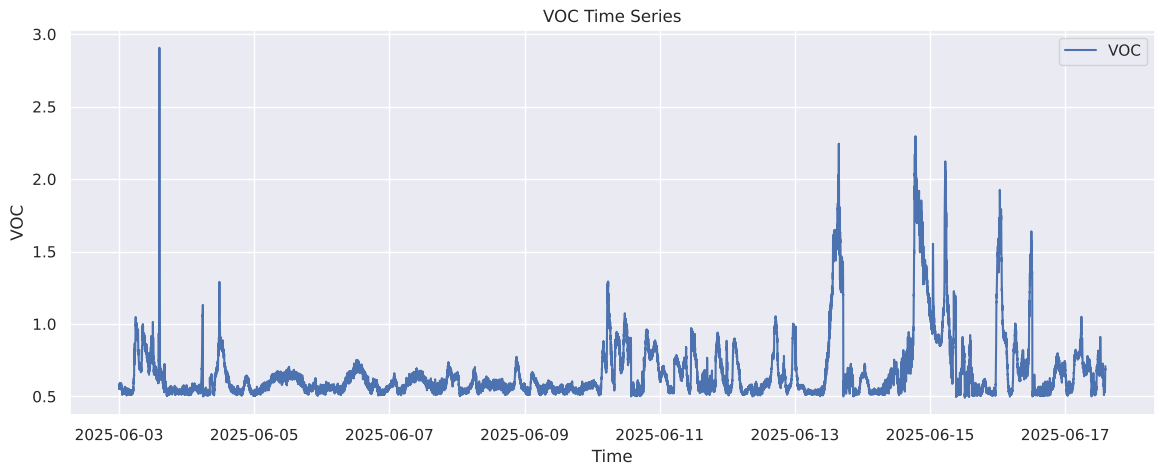

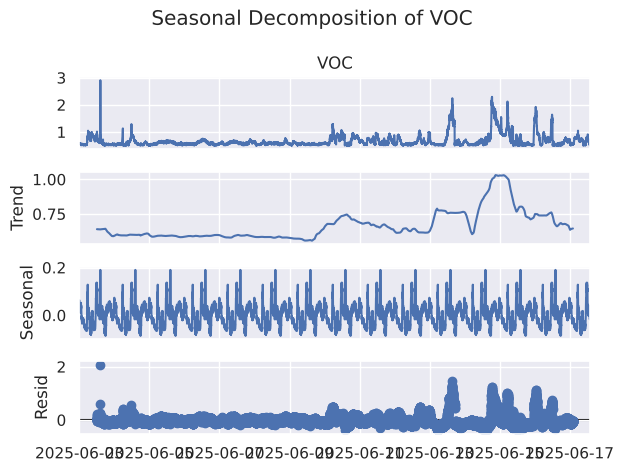

ADF Statistic: -7.954038553553211
p-value: 3.0712264873495654e-12
Critical Value 1%: -3.4306616708026687
Critical Value 5%: -2.8616777478966697
Critical Value 10%: -2.566843319379713


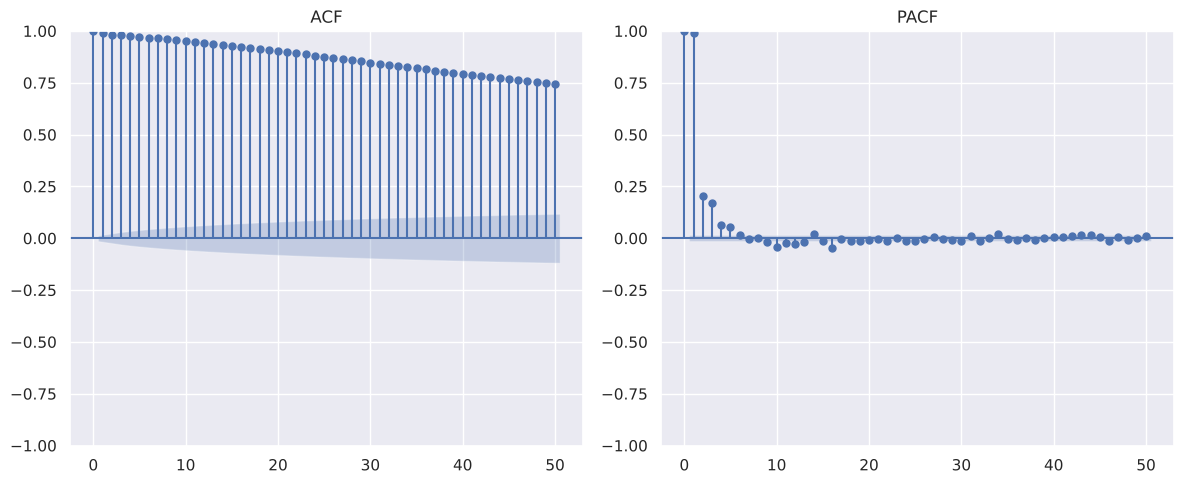

Fitting Auto ARIMA model...
Performing stepwise search to minimize aic


 ARIMA(1,1,1)(0,0,0)[0] intercept   : AIC=-86072.737, Time=8.18 sec


 ARIMA(0,1,0)(0,0,0)[0] intercept   : AIC=-84427.489, Time=1.26 sec


 ARIMA(1,1,0)(0,0,0)[0] intercept   : AIC=-85343.239, Time=1.38 sec


 ARIMA(0,1,1)(0,0,0)[0] intercept   : AIC=-85761.631, Time=4.31 sec


 ARIMA(0,1,0)(0,0,0)[0]             : AIC=-84429.488, Time=0.61 sec


... (11 outputs left out)

 ARIMA(0,1,3)(0,0,0)[0]             : AIC=-86131.538, Time=2.78 sec


 ARIMA(1,1,1)(0,0,0)[0]             : AIC=-86074.738, Time=3.14 sec


 ARIMA(1,1,3)(0,0,0)[0]             : AIC=-86129.587, Time=3.31 sec

Best model:  ARIMA(0,1,2)(0,0,0)[0]          
Total fit time: 78.900 seconds
                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                21018
Model:               SARIMAX(0, 1, 2)   Log Likelihood               43069.575
Date:                Mon, 26 Oct 2026   AIC                         -86133.150
Time:                        18:49:03   BIC                         -86109.291
Sample:                    06-03-2025   HQIC                        -86125.363
                         - 06-17-2025                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -0.2591      0.000   -608.081      0.000      -0.2

Forecast values that are NaN: 0 of 100


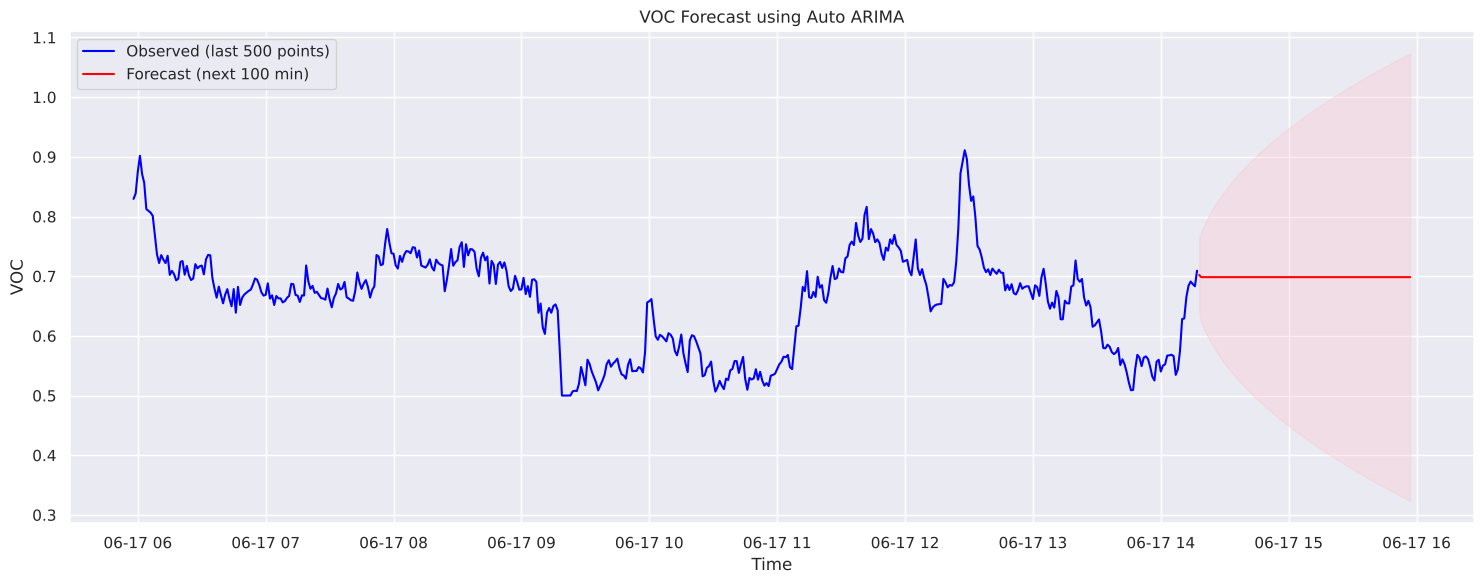

In [30]:
# --- Load and Prepare Data ---
df = pd.read_csv('../data/sensors_1min.csv')
df['time'] = pd.to_datetime(df['time'], format="ISO8601", utc=True)
df.set_index('time', inplace=True)

# Focus on VOC series on a regular 1-minute grid; the 2 empty minutes are filled by time interpolation
voc_series = df['VOC'].asfreq('1min').interpolate(method='time')

# --- Visualize Original VOC Time Series ---
plt.figure(figsize=(14, 5))
plt.plot(voc_series, label='VOC')
plt.title("VOC Time Series")
plt.xlabel("Time")
plt.ylabel("VOC")
plt.grid(True)
plt.legend()
plt.show()

# --- Seasonal Decomposition (Additive Model) ---
result = seasonal_decompose(voc_series, model='additive', period=1440)  # daily seasonality
result.plot()
plt.suptitle("Seasonal Decomposition of VOC")
plt.tight_layout()
plt.show()

# --- Stationarity Check with Augmented Dickey-Fuller Test ---
result_adf = adfuller(voc_series)
print("ADF Statistic:", result_adf[0])
print("p-value:", result_adf[1])
for key, value in result_adf[4].items():
    print(f'Critical Value {key}: {value}')

# --- Plot ACF and PACF ---
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plot_acf(voc_series, ax=plt.gca(), lags=50)
plt.title("ACF")

plt.subplot(1,2,2)
plot_pacf(voc_series, ax=plt.gca(), lags=50, method='ywm')
plt.title("PACF")
plt.tight_layout()
plt.show()

# --- Fit Auto ARIMA Model ---
print("Fitting Auto ARIMA model...")
model = auto_arima(
    voc_series,
    start_p=1, start_q=1,
    max_p=3, max_q=3,
    seasonal=False,
    d=1,
    trace=True,
    error_action='ignore',
    suppress_warnings=True,
    stepwise=True
)
print(model.summary())

# --- Forecast Next 100 Minutes ---
n_periods = 100
forecast, conf_int = model.predict(n_periods=n_periods, return_conf_int=True)
conf_int = np.asarray(conf_int)

# Create datetime index for forecast; np.asarray drops the model's own index so the values are not re-aligned to NaN
last_timestamp = voc_series.index[-1]
forecast_index = pd.date_range(start=last_timestamp + pd.Timedelta(minutes=1), periods=n_periods, freq='1min')
forecast_series = pd.Series(np.asarray(forecast), index=forecast_index)
print(f"Forecast values that are NaN: {int(forecast_series.isna().sum())} of {n_periods}")

# --- Plot Forecast Against Recent Observations ---
plt.figure(figsize=(15, 6))
plt.plot(voc_series[-500:], label='Observed (last 500 points)', color='blue')
plt.plot(forecast_series, label='Forecast (next 100 min)', color='red')
plt.fill_between(forecast_index, conf_int[:, 0], conf_int[:, 1], color='pink', alpha=0.3)
plt.title("VOC Forecast using Auto ARIMA")
plt.xlabel("Time")
plt.ylabel("VOC")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "voc_auto_arima_next_100_min.png", bbox_inches='tight')
plt.show()

In [31]:
# --- Leakage checks ---
checks = {
    "raw split: last train time < first test time": train_orig.index[-1] < test_orig.index[0],
    "raw z-score limits use training rows only": bool(np.isclose(train_mean, train_orig.mean()) and np.isclose(train_std, train_orig.std())),
    "raw cleaned test set equals the original test set (no test point dropped)": test_clean.equals(test_orig),
    "1-min split: last train time < first test time": train.index[-1] < test.index[0],
    "1-min z-score limits use training minutes only": bool(np.isclose(mu_1min, df_1min.iloc[:split_1min].mean()) and np.isclose(sd_1min, df_1min.iloc[:split_1min].std())),
    "1-min test minutes unchanged by cleaning": bool((df_clean.iloc[split_1min:] == df_1min.iloc[split_1min:]).all()),
    "1-min series is on a regular grid (freq = 1 min)": df_clean.index.freqstr in ("min", "T"),
}
for name, ok in checks.items():
    print(f"{name}: {ok}")
print("No model uses a feature at the target minute or later: the models here only use past values of the series.")

raw split: last train time < first test time: True
raw z-score limits use training rows only: True
raw cleaned test set equals the original test set (no test point dropped): True
1-min split: last train time < first test time: True
1-min z-score limits use training minutes only: True
1-min test minutes unchanged by cleaning: True
1-min series is on a regular grid (freq = 1 min): True
No model uses a feature at the target minute or later: the models here only use past values of the series.
